In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
train = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv"
)

test = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv"
)

print("Training Dataset:", train.shape)
print("Testing Dataset:", test.shape)

Training Dataset: (1460, 81)
Testing Dataset: (1459, 80)


In [3]:
# Display first 5 rows
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Check dataset information
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
# Statistical summary
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


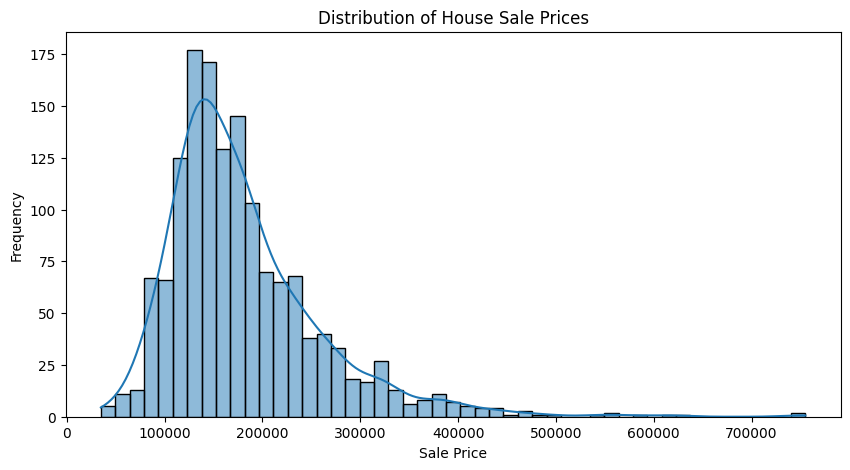

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(train["SalePrice"], kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

In [7]:
print("SalePrice Skewness:",
      train["SalePrice"].skew())

print("SalePrice Mean:",
      train["SalePrice"].mean())

print("SalePrice Median:",
      train["SalePrice"].median())

SalePrice Skewness: 1.8828757597682129
SalePrice Mean: 180921.19589041095
SalePrice Median: 163000.0


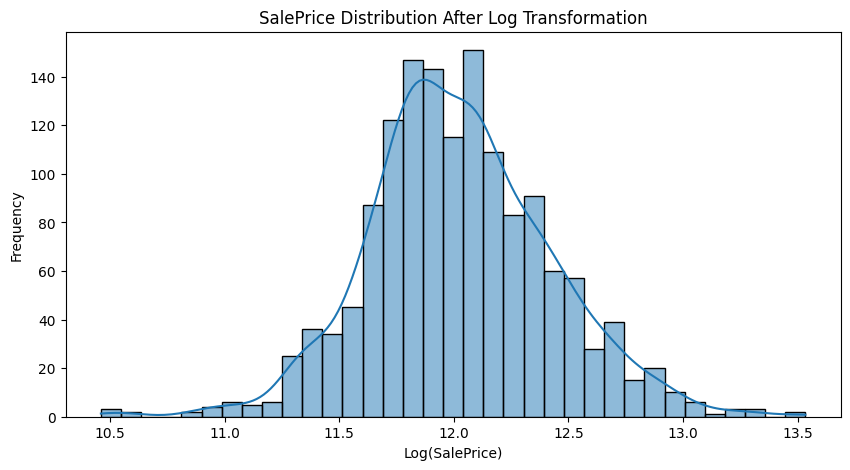

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(train["SalePrice"]), kde=True)

plt.title("SalePrice Distribution After Log Transformation")
plt.xlabel("Log(SalePrice)")
plt.ylabel("Frequency")

plt.show()

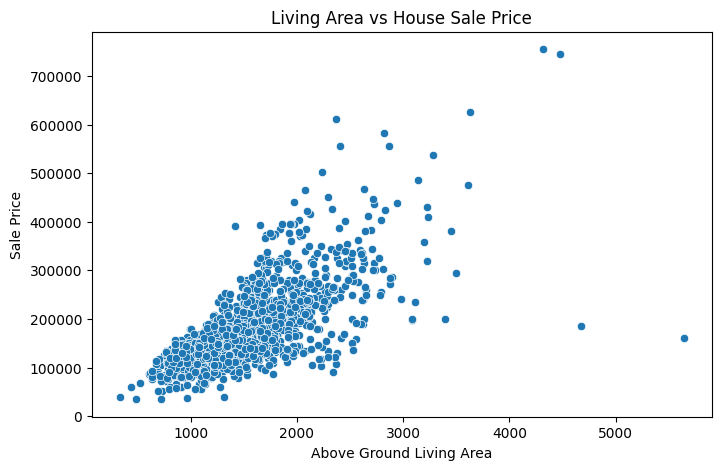

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")

plt.show()

In [10]:
# Calculate correlation with SalePrice

correlation = train.corr(numeric_only=True)["SalePrice"]

top_features = correlation.abs().sort_values(
    ascending=False
).head(15)

print(top_features)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


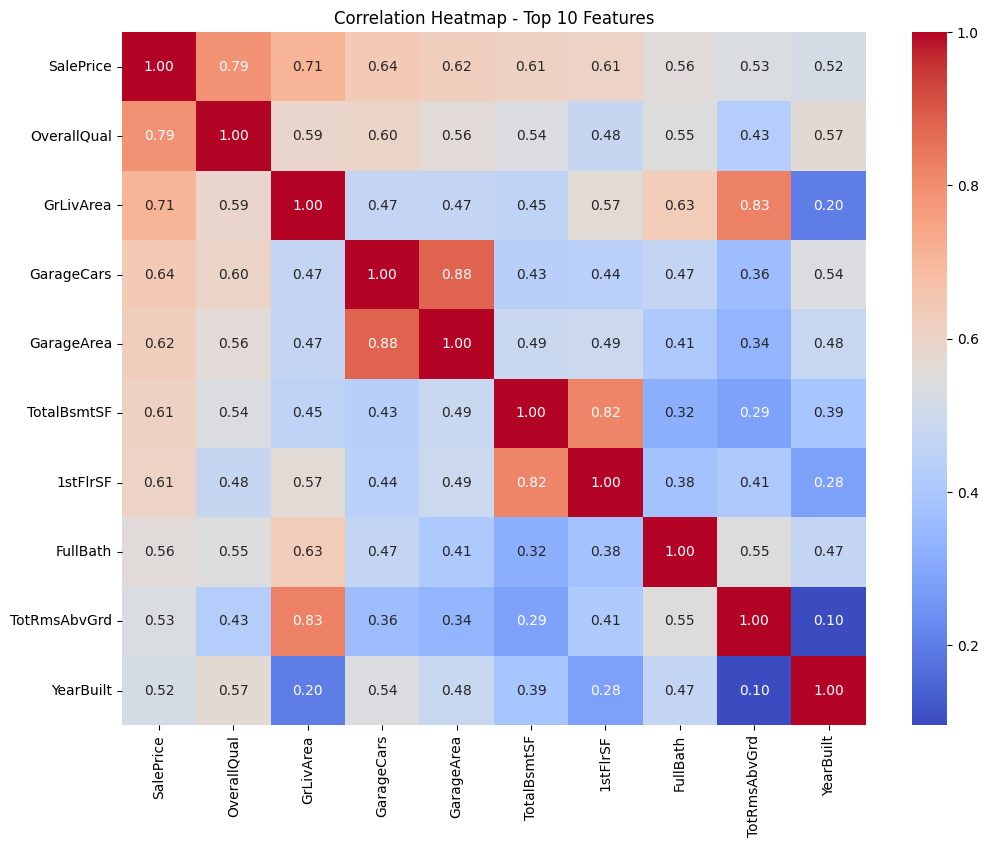

In [11]:
plt.figure(figsize=(12, 9))

top_10 = correlation.abs().sort_values(
    ascending=False
).head(10).index

sns.heatmap(
    train[top_10].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Top 10 Features")
plt.show()

In [12]:
outliers = train[
    (train["GrLivArea"] > 4000) &
    (train["SalePrice"] < 200000)
]

outliers[["Id", "GrLivArea", "SalePrice"]]

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


In [14]:
correlation = train.corr(numeric_only=True)["SalePrice"]

top_features = correlation.abs().sort_values(
    ascending=False
).head(15)

print(top_features)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


In [15]:
# Check missing values in training dataset

missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

missing_percentage = (
    missing / len(train) * 100
)

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

print(missing_summary)

              Missing Values  Percentage
PoolQC                  1453   99.520548
MiscFeature             1406   96.301370
Alley                   1369   93.767123
Fence                   1179   80.753425
MasVnrType               872   59.726027
FireplaceQu              690   47.260274
LotFrontage              259   17.739726
GarageType                81    5.547945
GarageYrBlt               81    5.547945
GarageFinish              81    5.547945
GarageQual                81    5.547945
GarageCond                81    5.547945
BsmtExposure              38    2.602740
BsmtFinType2              38    2.602740
BsmtQual                  37    2.534247
BsmtCond                  37    2.534247
BsmtFinType1              37    2.534247
MasVnrArea                 8    0.547945
Electrical                 1    0.068493


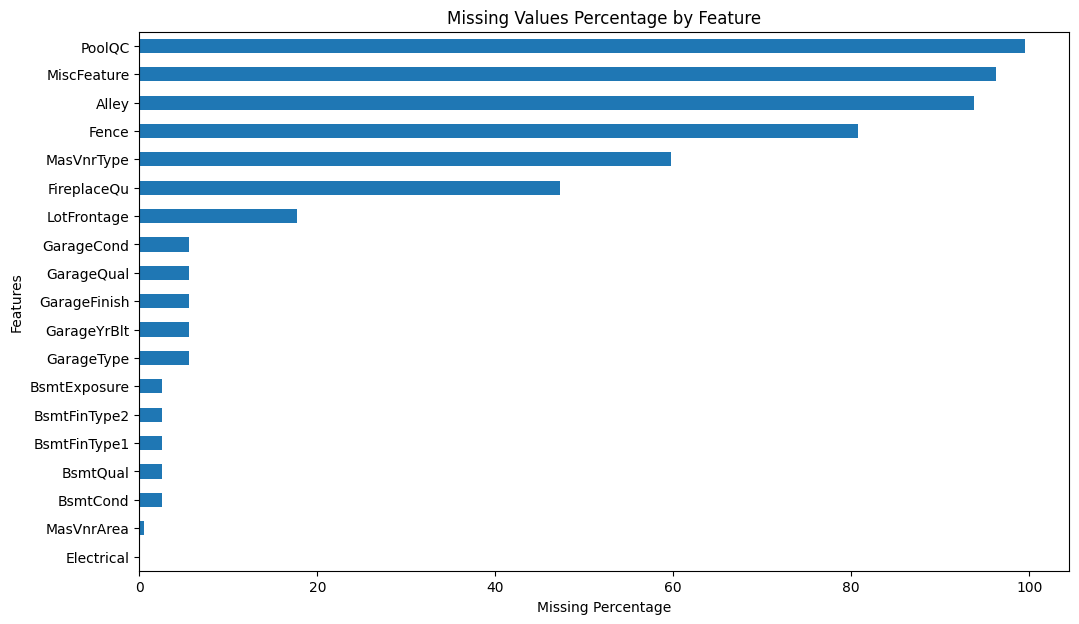

In [16]:
plt.figure(figsize=(12, 7))

missing_summary["Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values Percentage by Feature")
plt.xlabel("Missing Percentage")
plt.ylabel("Features")

plt.show()

In [17]:
# Combine train and test features for inspection

all_features = pd.concat(
    [
        train.drop(columns=["SalePrice"]),
        test
    ],
    axis=0,
    ignore_index=True
)

missing_info = pd.DataFrame({
    "Missing_Count": all_features.isnull().sum(),
    "Missing_Percentage": (
        all_features.isnull().mean() * 100
    ),
    "Data_Type": all_features.dtypes
})

missing_info = missing_info[
    missing_info["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_info.to_string())

              Missing_Count  Missing_Percentage Data_Type
PoolQC                 2909           99.657417    object
MiscFeature            2814           96.402878    object
Alley                  2721           93.216855    object
Fence                  2348           80.438506    object
MasVnrType             1766           60.500171    object
FireplaceQu            1420           48.646797    object
LotFrontage             486           16.649538   float64
GarageQual              159            5.447071    object
GarageYrBlt             159            5.447071   float64
GarageCond              159            5.447071    object
GarageFinish            159            5.447071    object
GarageType              157            5.378554    object
BsmtExposure             82            2.809181    object
BsmtCond                 82            2.809181    object
BsmtQual                 81            2.774923    object
BsmtFinType2             80            2.740665    object
BsmtFinType1  

In [18]:
# Create a combined dataset for preprocessing
all_features = pd.concat(
    [train.drop(columns=["SalePrice"]), test],
    axis=0,
    ignore_index=True
)

# Features where missing means the property does not have that feature
none_columns = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "MasVnrType", "FireplaceQu",
    "GarageType", "GarageFinish",
    "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond",
    "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2"
]

for col in none_columns:
    all_features[col] = all_features[col].fillna("None")

print("Categorical missing values handled!")

Categorical missing values handled!


In [19]:
# Missing numerical values indicating absence of a structure
zero_columns = [
    "MasVnrArea",
    "BsmtFullBath", "BsmtHalfBath",
    "BsmtFinSF1", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF",
    "GarageCars", "GarageArea",
    "GarageYrBlt"
]

for col in zero_columns:
    all_features[col] = all_features[col].fillna(0)

print("Numerical missing values handled!")

Numerical missing values handled!


In [20]:
all_features["LotFrontage"] = (
    all_features.groupby("Neighborhood")["LotFrontage"]
    .transform(lambda x: x.fillna(x.median()))
)

all_features["LotFrontage"] = (
    all_features["LotFrontage"].fillna(
        all_features["LotFrontage"].median()
    )
)

print("LotFrontage handled!")

LotFrontage handled!


In [21]:
remaining = all_features.isnull().sum()

remaining = remaining[remaining > 0].sort_values(
    ascending=False
)

print("Remaining missing values:")
print(remaining)

Remaining missing values:
MSZoning       4
Utilities      2
Functional     2
Exterior1st    1
Exterior2nd    1
Electrical     1
KitchenQual    1
SaleType       1
dtype: int64


In [22]:
# Fill remaining categorical missing values using mode

for col in remaining.index:
    all_features[col] = all_features[col].fillna(
        all_features[col].mode()[0]
    )

print("All missing values handled successfully!")

print("Total missing values:", all_features.isnull().sum().sum())

All missing values handled successfully!
Total missing values: 0


In [23]:
# Feature Engineering

all_features["TotalSF"] = (
    all_features["TotalBsmtSF"] +
    all_features["1stFlrSF"] +
    all_features["2ndFlrSF"]
)

all_features["TotalBathrooms"] = (
    all_features["FullBath"] +
    0.5 * all_features["HalfBath"] +
    all_features["BsmtFullBath"] +
    0.5 * all_features["BsmtHalfBath"]
)

all_features["HouseAge"] = (
    all_features["YrSold"] - all_features["YearBuilt"]
)

all_features["RemodAge"] = (
    all_features["YrSold"] - all_features["YearRemodAdd"]
)

all_features["TotalPorchSF"] = (
    all_features["OpenPorchSF"] +
    all_features["EnclosedPorch"] +
    all_features["3SsnPorch"] +
    all_features["ScreenPorch"]
)

print("Feature Engineering completed!")

print(all_features[
    ["TotalSF", "TotalBathrooms", "HouseAge",
     "RemodAge", "TotalPorchSF"]
].head())

Feature Engineering completed!
   TotalSF  TotalBathrooms  HouseAge  RemodAge  TotalPorchSF
0   2566.0             3.5         5         5            61
1   2524.0             2.5        31        31             0
2   2706.0             3.5         7         6            42
3   2473.0             2.0        91        36           307
4   3343.0             3.5         8         8            84


In [24]:
# Convert categorical features into numerical values

all_features = pd.get_dummies(
    all_features,
    drop_first=True,
    dtype=int
)

print("Categorical Encoding completed!")
print("Final dataset shape:", all_features.shape)

print("Any missing values:", all_features.isnull().sum().sum())

print(all_features.head())

Categorical Encoding completed!
Final dataset shape: (2919, 265)
Any missing values: 0
   Id  MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  YearBuilt  \
0   1          60         65.0     8450            7            5       2003   
1   2          20         80.0     9600            6            8       1976   
2   3          60         68.0    11250            7            5       2001   
3   4          70         60.0     9550            7            5       1915   
4   5          60         84.0    14260            8            5       2000   

   YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  SaleType_ConLI  SaleType_ConLw  \
0          2003       196.0       706.0  ...               0               0   
1          1976         0.0       978.0  ...               0               0   
2          2002       162.0       486.0  ...               0               0   
3          1970         0.0       216.0  ...               0               0   
4          2000       350.0     

In [25]:
# Separate training and testing datasets

X = all_features.iloc[:len(train)].drop("Id", axis=1)

X_test = all_features.iloc[len(train):].drop("Id", axis=1)

y = train["SalePrice"]

print("Training Features:", X.shape)
print("Testing Features:", X_test.shape)
print("Target Variable:", y.shape)

Training Features: (1460, 264)
Testing Features: (1459, 264)
Target Variable: (1460,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Training Target:", y_train.shape)
print("Validation Target:", y_val.shape)

Training Set: (1168, 264)
Validation Set: (292, 264)
Training Target: (1168,)
Validation Target: (292,)


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make validation predictions
val_predictions = rf_model.predict(X_val)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))

print("Random Forest Model Training Completed!")
print("Validation RMSE:", round(rmse, 2))

Random Forest Model Training Completed!
Validation RMSE: 29595.31


In [29]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_samples_split=2,
    loss="huber",
    random_state=42
)

# Train model
gb_model.fit(X_train, y_train)

# Validation predictions
gb_predictions = gb_model.predict(X_val)

# Calculate RMSE
gb_rmse = np.sqrt(
    mean_squared_error(y_val, gb_predictions)
)

print("Gradient Boosting Training Completed!")
print("Gradient Boosting RMSE:", round(gb_rmse, 2))
print("Random Forest RMSE:", round(rmse, 2))

Gradient Boosting Training Completed!
Gradient Boosting RMSE: 28705.53
Random Forest RMSE: 29595.31


In [31]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Create Extra Trees model
et_model = ExtraTreesRegressor(
    n_estimators=500,
    max_features=0.8,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Train model
et_model.fit(X_train, y_train)

# Make predictions
et_predictions = et_model.predict(X_val)

# Calculate RMSE
et_rmse = np.sqrt(
    mean_squared_error(y_val, et_predictions)
)

print("Extra Trees Training Completed!")
print("Extra Trees RMSE:", round(et_rmse, 2))
print("Random Forest RMSE:", round(rmse, 2))
print("Gradient Boosting RMSE:", round(gb_rmse, 2))

Extra Trees Training Completed!
Extra Trees RMSE: 28099.37
Random Forest RMSE: 29595.31
Gradient Boosting RMSE: 28705.53


In [33]:
# Combine Gradient Boosting and Extra Trees

ensemble_predictions = (
    0.5 * gb_predictions +
    0.5 * et_predictions
)

ensemble_rmse = np.sqrt(
    mean_squared_error(y_val, ensemble_predictions)
)

print("Ensemble Model Results")
print("Ensemble RMSE:", round(ensemble_rmse, 2))
print("Extra Trees RMSE:", round(et_rmse, 2))

Ensemble Model Results
Ensemble RMSE: 27595.16
Extra Trees RMSE: 28099.37


In [34]:
# Train final models on complete training data

final_gb = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_samples_split=2,
    loss="huber",
    random_state=42
)

final_et = ExtraTreesRegressor(
    n_estimators=500,
    max_features=0.8,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

final_gb.fit(X, y)
final_et.fit(X, y)

print("Final models trained successfully!")

Final models trained successfully!


In [35]:
# Predict house prices using both final models

final_gb_predictions = final_gb.predict(X_test)
final_et_predictions = final_et.predict(X_test)

# Combine predictions
final_predictions = (
    0.5 * final_gb_predictions +
    0.5 * final_et_predictions
)

print("Final predictions generated!")
print("Total predictions:", len(final_predictions))
print("First 10 predictions:")
print(final_predictions[:10])

Final predictions generated!
Total predictions: 1459
First 10 predictions:
[122452.13891105 158211.94180495 180211.47658808 188627.28181973
 188151.4422848  177560.22800302 175216.53495881 170838.30698838
 187465.67987971 127562.65597241]


In [36]:
# Create final submission file

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": final_predictions
})

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("Submission file created successfully!")
print(submission.head())
print("Submission shape:", submission.shape)

Submission file created successfully!
     Id      SalePrice
0  1461  122452.138911
1  1462  158211.941805
2  1463  180211.476588
3  1464  188627.281820
4  1465  188151.442285
Submission shape: (1459, 2)
